In [24]:
from pathlib import Path
import os, json, random, subprocess

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
import cv2

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             recall_score, precision_score, confusion_matrix, ConfusionMatrixDisplay)

print(f"Tensorflow:{tf.__version__}, OpenCV:{cv2.__version__}")
print(f"GPU:{tf.config.list_physical_devices("GPU")}")

Tensorflow:2.21.0, OpenCV:5.0.0
GPU:[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [25]:
SEED = 42
IMG_SIZE = 224
DEFECT_CUTOFF = 0.5
BATCH_SIZE = 32
EPOCHS = 30
LR = 1e-3

OUT_DIR = Path("outputs"); OUT_DIR.mkdir(parents=True,exist_ok=True)

def set_seeds(seed=SEED):
  random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
  os.environ["PYTHON_HASH_SEED"] = str(SEED)
set_seeds()

In [26]:
# get data
REPO_DIR = Path("elpv-dataset")
if not REPO_DIR.exists():
    subprocess.run(["git", "clone", "--depth", "1",
                    "https://github.com/zae-bayern/elpv-dataset.git", str(REPO_DIR)], check=True)

# The repo stores data under src/elpv_dataset/data
DATA_DIR = next(p for p in [REPO_DIR / "src/elpv_dataset/data", REPO_DIR] if (p / "labels.csv").exists())
print("Data dir:", DATA_DIR)


Data dir: elpv-dataset/src/elpv_dataset/data


# 1. Load and audit labels

In [27]:
df = pd.read_csv(DATA_DIR / 'labels.csv', sep=r"\s+", header=None, names=['path', 'prob', 'type'])
print(f"Dataset rows and columns: {df.shape}")


Dataset rows and columns: (2624, 3)


In [28]:
df['prob'] = round(df['prob'],2)
df['label'] = (df['prob'] >= DEFECT_CUTOFF).astype(int) # 1 = defective
df['strata'] = df['label'].astype(str) + '_' + df['type']
df['filepath'] = df['path'].apply(lambda p : str(DATA_DIR / p))


display(pd.crosstab(df['prob'], df['type'], margins=True))
display(pd.crosstab(df['label'], df['type'], margins=True, normalize='columns').round(3))
print(f"Defect rate: {df.label.mean():.1%}  -> a model that always says 'OK' scores {1-df.label.mean():.1%} accuracy.")

type,mono,poly,All
prob,,,
0.0,588,920,1508
0.33,117,178,295
0.67,56,50,106
1.0,313,402,715
All,1074,1550,2624


type,mono,poly,All
label,,,
0,0.656,0.708,0.687
1,0.344,0.292,0.313


Defect rate: 31.3%  -> a model that always says 'OK' scores 68.7% accuracy.


Class balance: ~31% defective → accuracy is misleading. Therefore, PR-AUC and recall are used on defective cells.

# 2. Data Analysis

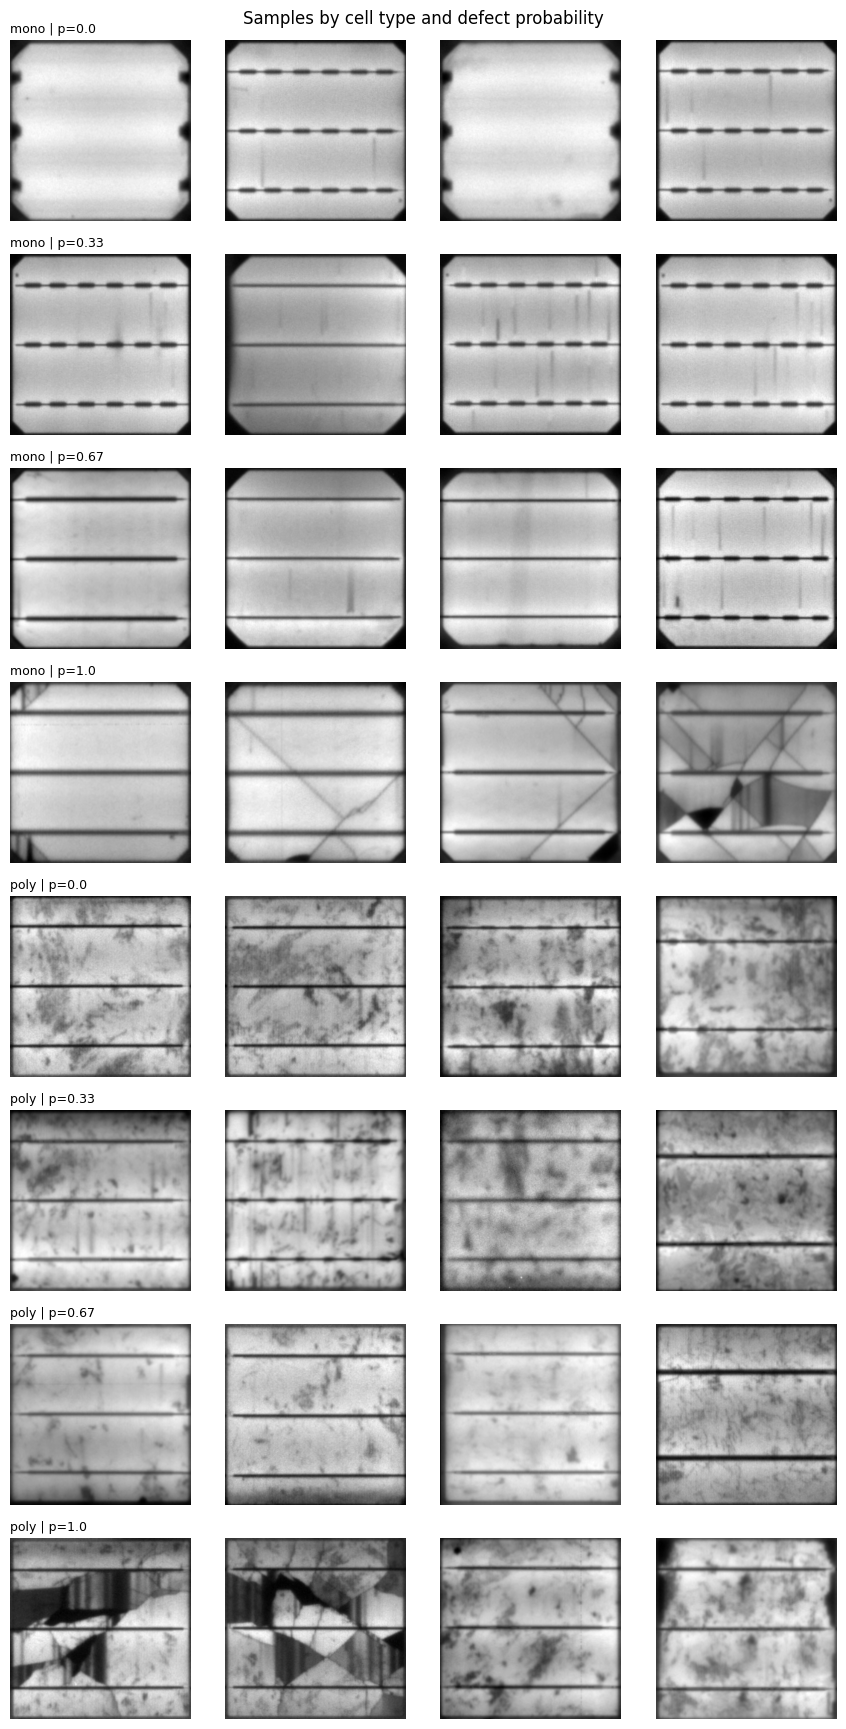

In [29]:
def show_grid(frame, n_per_group=4, title=""):
    groups = frame.groupby(["type", "prob"])
    fig, axes = plt.subplots(len(groups), n_per_group, figsize=(2.2 * n_per_group, 2.2 * len(groups)))
    for r, ((t, p), g) in enumerate(groups):
        for c, (_, row) in enumerate(g.sample(min(n_per_group, len(g)), random_state=SEED).iterrows()):
            axes[r, c].imshow(cv2.imread(row.filepath, cv2.IMREAD_GRAYSCALE), cmap="gray")
            axes[r, c].axis("off")
        axes[r, 0].set_title(f"{t} | p={p}", fontsize=9, loc="left")
    fig.suptitle(title); plt.tight_layout(); plt.show()

show_grid(df, title="Samples by cell type and defect probability")

mean_int  std_int
type label                   
mono 0         164.2     29.3
     1         141.0     29.7
poly 0         157.5     28.5
     1         129.4     29.6

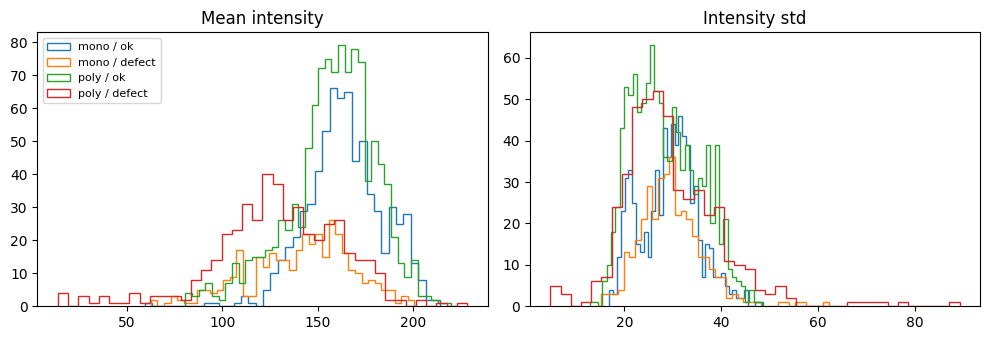

In [30]:
# Intensity statistics: mono vs poly, functional vs defective
def img_stats(fp):
    im = cv2.imread(fp, cv2.IMREAD_GRAYSCALE)
    return im.mean(), im.std()

df[["mean_int", "std_int"]] = np.array([img_stats(fp) for fp in df.filepath])
display(df.groupby(["type", "label"])[["mean_int", "std_int"]].mean().round(1))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
for t in ["mono", "poly"]:
    for lbl, ls in [(0, "-"), (1, "--")]:
        d = df[(df.type == t) & (df.label == lbl)]
        ax[0].hist(d.mean_int, bins=40, histtype="step", ls=ls, label=f"{t} / {'defect' if lbl else 'ok'}")
        ax[1].hist(d.std_int, bins=40, histtype="step", ls=ls, label=f"{t} / {'defect' if lbl else 'ok'}")
ax[0].set_title("Mean intensity"); ax[1].set_title("Intensity std"); ax[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

# 3. Stratified split (label × cell type)

In [31]:
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df["strata"], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["strata"], random_state=SEED)

for name, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(f"{name:5s} n={len(d):4d}  defect rate={d.label.mean():.3f}  poly share={(d.type=='poly').mean():.3f}")

splits = pd.concat([train_df.assign(split="train"), val_df.assign(split="val"), test_df.assign(split="test")])
splits[["path", "prob", "type", "label", "split"]].to_csv("outputs/splits.csv", index=False)
print("Saved outputs/splits.csv")

train n=1836  defect rate=0.313  poly share=0.590
val   n= 394  defect rate=0.315  poly share=0.591
test  n= 394  defect rate=0.312  poly share=0.591
Saved outputs/splits.csv


# 4. OpenCV preprocessing

EL images vary in exposure between modules. **CLAHE** (Contrast Limited Adaptive Histogram Equalization) normalises local contrast so faint cracks stand out,
and a light **median blur** removes salt-and-pepper sensor noise without smearing thin crack lines (a Gaussian blur would).

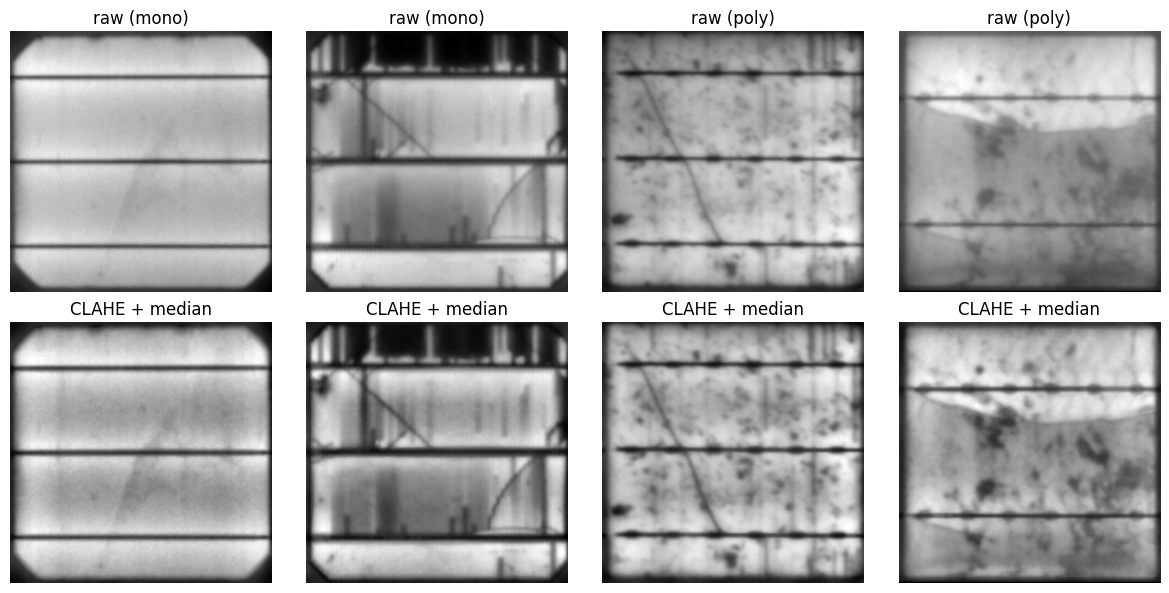

In [32]:
CLAHE = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

def preprocess(fp, size=IMG_SIZE):
    """Read EL cell image -> CLAHE -> median denoise -> resize. Returns uint8 HxW."""
    im = cv2.imread(fp, cv2.IMREAD_GRAYSCALE)
    im = CLAHE.apply(im)
    im = cv2.medianBlur(im, 3)
    return cv2.resize(im, (size, size), interpolation=cv2.INTER_AREA)

# Before / after on defective examples
ex = df[df.label == 1].groupby("type").sample(2, random_state=SEED)
fig, axes = plt.subplots(2, len(ex), figsize=(3 * len(ex), 6))
for i, (_, row) in enumerate(ex.iterrows()):
    axes[0, i].imshow(cv2.imread(row.filepath, cv2.IMREAD_GRAYSCALE), cmap="gray"); axes[0, i].set_title(f"raw ({row.type})")
    axes[1, i].imshow(preprocess(row.filepath, 300), cmap="gray"); axes[1, i].set_title("CLAHE + median")
    axes[0, i].axis("off"); axes[1, i].axis("off")
plt.tight_layout(); plt.show()

In [33]:
# Preprocess once and cache in memory (2,624 x 224 x 224 uint8 ≈ 130 MB)
def load_split(d):
    X = np.stack([preprocess(fp) for fp in d.filepath])
    return X, d["label"].values, d["type"].values

X_train, y_train, t_train = load_split(train_df)
X_val, y_val, t_val = load_split(val_df)
X_test, y_test, t_test = load_split(test_df)
print(X_train.shape, X_val.shape, X_test.shape)

(1836, 224, 224) (394, 224, 224) (394, 224, 224)


# 5. Shared evaluation function

In [34]:
def evaluate(y_true, y_score, types, threshold=0.5, name="model", plot=True):
    """Inspection-oriented metrics, overall and per cell type."""
    y_pred = (y_score >= threshold).astype(int)
    rows = []
    for grp, mask in [("all", np.ones_like(y_true, bool)), ("mono", types == "mono"), ("poly", types == "poly")]:
        yt, ys, yp = y_true[mask], y_score[mask], y_pred[mask]
        tn, fp, fn, tp = confusion_matrix(yt, yp, labels=[0, 1]).ravel()
        rows.append(dict(model=name, group=grp, n=int(mask.sum()),
                         pr_auc=average_precision_score(yt, ys), roc_auc=roc_auc_score(yt, ys),
                         recall_defect=recall_score(yt, yp, zero_division=0),
                         precision_defect=precision_score(yt, yp, zero_division=0),
                         missed_defects=int(fn), false_rejects=int(fp)))
    res = pd.DataFrame(rows).round(3)
    if plot:
        fig, ax = plt.subplots(1, 2, figsize=(10, 4))
        for grp in ["mono", "poly"]:
            m = types == grp
            p, r, _ = precision_recall_curve(y_true[m], y_score[m])
            ax[0].plot(r, p, label=f"{grp} (AP={average_precision_score(y_true[m], y_score[m]):.2f})")
        ax[0].axhline(y_true.mean(), ls=":", c="gray", label="no-skill")
        ax[0].set(xlabel="Recall (defects caught)", ylabel="Precision", title=f"{name}: PR curve"); ax[0].legend()
        ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred), display_labels=["OK", "Defect"]).plot(ax=ax[1], colorbar=False)
        ax[1].set_title(f"Confusion matrix @ threshold {threshold}")
        plt.tight_layout(); plt.show()
    return res

# 6. Classical OpenCV baseline

Before reaching for deep learning: how far do hand-crafted features get?
- **Black-hat morphology** highlights thin dark structures (cracks) on a bright background
- **Dark-area fraction** captures electrically inactive (disconnected) regions
- **Canny edge density** and **Laplacian variance** capture texture / sharp discontinuities

Caveat: busbars and poly grain boundaries are also dark lines — this is exactly where hand-crafted features should struggle.

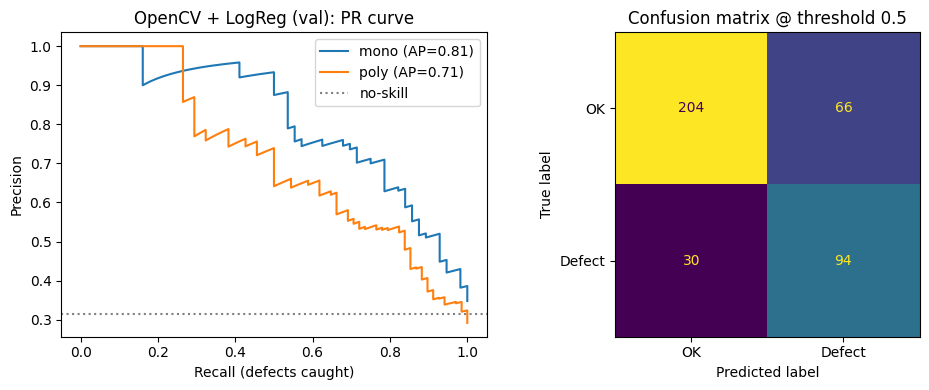

,model,group,n,pr_auc,roc_auc,recall_defect,precision_defect,missed_defects,false_rejects
0,OpenCV + LogReg (val),all,394,0.744,0.833,0.758,0.588,30,66
1,OpenCV + LogReg (val),mono,161,0.808,0.863,0.821,0.639,10,26
2,OpenCV + LogReg (val),poly,233,0.709,0.818,0.706,0.545,20,40


In [35]:
KERNEL = cv2.getStructuringElement(cv2.MORPH_RECT, (15, 15))

def handcrafted_features(im):
    blackhat = cv2.morphologyEx(im, cv2.MORPH_BLACKHAT, KERNEL)
    edges = cv2.Canny(im, 50, 150)
    return [im.mean(), im.std(),
            blackhat.mean(), np.percentile(blackhat, 99), (blackhat > 40).mean(),
            (im < 40).mean(),                       # dark / inactive area fraction
            (edges > 0).mean(),
            cv2.Laplacian(im, cv2.CV_64F).var()]

feat = lambda X: np.array([handcrafted_features(im) for im in X])
F_train, F_val, F_test = feat(X_train), feat(X_val), feat(X_test)

clf = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000))
clf.fit(F_train, y_train)
res_classical = evaluate(y_val, clf.predict_proba(F_val)[:, 1], t_val, name="OpenCV + LogReg (val)")
display(res_classical)

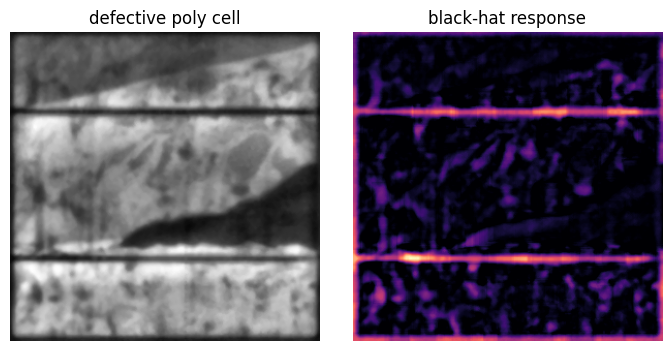

In [36]:
# What does black-hat actually highlight? (sanity check, good README figure)
row = val_df[val_df.label == 1].iloc[0]
im = preprocess(row.filepath, 300)
bh = cv2.morphologyEx(im, cv2.MORPH_BLACKHAT, KERNEL)
fig, ax = plt.subplots(1, 2, figsize=(7, 3.5))
ax[0].imshow(im, cmap="gray"); ax[0].set_title(f"defective {row.type} cell")
ax[1].imshow(bh, cmap="magma"); ax[1].set_title("black-hat response")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

# 7. `tf.data` pipeline with physically valid augmentation

Allowed: horizontal/vertical flips and 90° rotations (a crack is still a crack).
Deliberately **excluded**: strong brightness/contrast jitter (can erase faint cracks or fake dark regions) and elastic warps (can bend busbars into crack-like shapes).

In [37]:
AUTOTUNE = tf.data.AUTOTUNE

def augment(x, y):
    x = tf.image.random_flip_left_right(x)
    x = tf.image.random_flip_up_down(x)
    x = tf.image.rot90(x, k=tf.random.uniform([], 0, 4, dtype=tf.int32))
    return x, y

def make_ds(X, y, training=False):
    ds = tf.data.Dataset.from_tensor_slices((X[..., None], y.astype("float32")))
    ds = ds.map(lambda x, y: (tf.cast(x, tf.float32) / 255.0, y), num_parallel_calls=AUTOTUNE)
    if training:
        ds = ds.shuffle(len(X), seed=SEED).map(augment, num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

ds_train, ds_val, ds_test = make_ds(X_train, y_train, True), make_ds(X_val, y_val), make_ds(X_test, y_test)

# 8. Small CNN baseline

In [38]:
def build_small_cnn(img_size=IMG_SIZE):
    inp = tf.keras.Input((img_size, img_size, 1))
    x = inp
    for f in [32, 64, 128, 256]:
        x = tf.keras.layers.Conv2D(f, 3, padding="same", use_bias=False)(x)
        x = tf.keras.layers.BatchNormalization()(x)
        x = tf.keras.layers.ReLU()(x)
        x = tf.keras.layers.MaxPooling2D()(x)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dropout(0.3)(x)
    out = tf.keras.layers.Dense(1, activation="sigmoid")(x)
    return tf.keras.Model(inp, out, name="small_cnn")

model = build_small_cnn()
model.compile(optimizer=tf.keras.optimizers.Adam(LR), loss="binary_crossentropy",
              metrics=[tf.keras.metrics.AUC(curve="PR", name="pr_auc"),
                       tf.keras.metrics.Recall(name="recall"), tf.keras.metrics.Precision(name="precision")])
model.summary()

# Class weights: make a missed defect "cost" as much in the loss as the imbalance implies
n_pos, n_neg = y_train.sum(), len(y_train) - y_train.sum()
class_weight = {0: len(y_train) / (2 * n_neg), 1: len(y_train) / (2 * n_pos)}
print("class weights:", {k: round(v, 2) for k, v in class_weight.items()})

Model: "small_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 224, 224, 32)   │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_4 (ReLU)                  │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_5 (ReLU)                  │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_6 (ReLU)                  │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 28, 28, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_7 (ReLU)                  │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 389,537 (1.49 MB)

 Trainable params: 388,577 (1.48 MB)

 Non-trainable params: 960 (3.75 KB)

class weights: {0: np.float64(0.73), 1: np.float64(1.6)}


Epoch 1/30
58/58 - 16s - 282ms/step - loss: 0.6379 - pr_auc: 0.5809 - precision: 0.4744 - recall: 0.6446 - val_loss: 0.7284 - val_pr_auc: 0.2776 - val_precision: 0.3147 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 2/30
58/58 - 11s - 197ms/step - loss: 0.5724 - pr_auc: 0.6507 - precision: 0.5391 - recall: 0.6969 - val_loss: 0.6720 - val_pr_auc: 0.2275 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 0.0010
Epoch 3/30
58/58 - 5s - 86ms/step - loss: 0.5654 - pr_auc: 0.6395 - precision: 0.5332 - recall: 0.6864 - val_loss: 0.7644 - val_pr_auc: 0.2163 - val_precision: 0.3023 - val_recall: 0.9435 - learning_rate: 0.0010
Epoch 4/30
58/58 - 5s - 87ms/step - loss: 0.5622 - pr_auc: 0.6526 - precision: 0.5286 - recall: 0.6916 - val_loss: 0.6256 - val_pr_auc: 0.2691 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 0.0010
Epoch 5/30
58/58 - 5s - 87ms/step - loss: 0.5560 - pr_auc: 0.6502 - precision: 0.5333 - recall: 0.7247 - val_loss: 0.7041 - val_pr_a

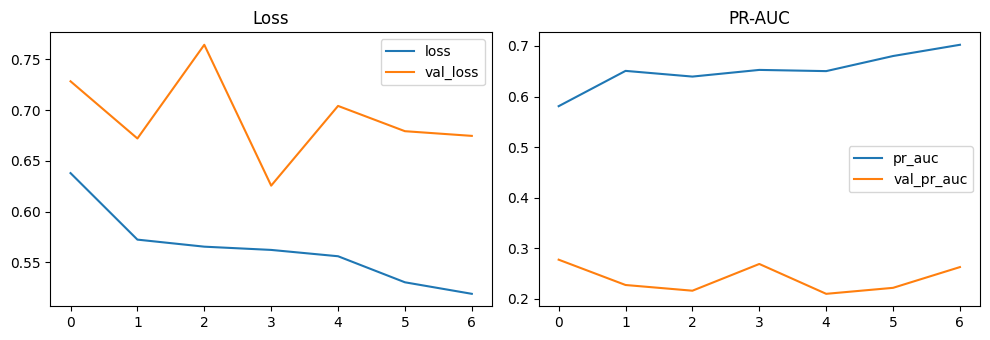

In [39]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor="val_pr_auc", mode="max", patience=6, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_pr_auc", mode="max", factor=0.5, patience=3),
]
history = model.fit(ds_train, validation_data=ds_val, epochs=EPOCHS,
                    class_weight=class_weight, callbacks=callbacks, verbose=2)

h = pd.DataFrame(history.history)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
h[["loss", "val_loss"]].plot(ax=ax[0], title="Loss"); h[["pr_auc", "val_pr_auc"]].plot(ax=ax[1], title="PR-AUC")
plt.tight_layout(); plt.show()

# 9. Compare baselines on validation

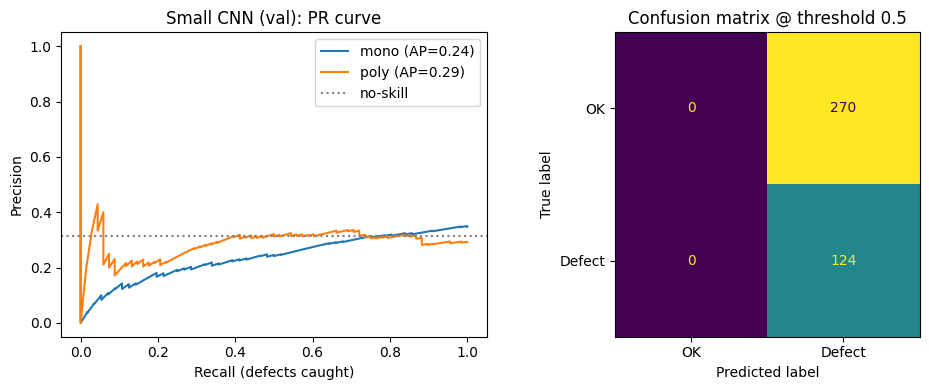

,model,group,n,pr_auc,roc_auc,recall_defect,precision_defect,missed_defects,false_rejects
0,OpenCV + LogReg (val),all,394,0.744,0.833,0.758,0.588,30,66
1,OpenCV + LogReg (val),mono,161,0.808,0.863,0.821,0.639,10,26
2,OpenCV + LogReg (val),poly,233,0.709,0.818,0.706,0.545,20,40
0,Small CNN (val),all,394,0.277,0.469,1.000,0.315,0,270
1,Small CNN (val),mono,161,0.243,0.270,1.000,0.348,0,105
2,Small CNN (val),poly,233,0.294,0.515,1.000,0.292,0,165


In [40]:
val_score_cnn = model.predict(ds_val, verbose=0).ravel()
res_cnn = evaluate(y_val, val_score_cnn, t_val, name="Small CNN (val)")
comparison = pd.concat([res_classical, res_cnn])
display(comparison)

In [41]:
# Save model versioned with its config + metrics
model.save(OUT_DIR / "small_cnn.keras")
comparison.to_csv(OUT_DIR / "baseline_comparison_val.csv", index=False)
json.dump({"seed": SEED, "img_size": IMG_SIZE, "defect_cutoff": DEFECT_CUTOFF, "batch_size": BATCH_SIZE,
           "epochs_run": len(history.history["loss"]), "lr": LR, "preprocess": "CLAHE(2.0,8x8)+median3",
           "val_metrics": res_cnn.to_dict(orient="records")},
          open(OUT_DIR / "small_cnn_run.json", "w"), indent=2)
print("Saved to", OUT_DIR)


Saved to outputs
